# Phase 6-R2 — KUB Characterization & Publication-Ready Data Analysis

This notebook provides a rigorous, publication-ready characterization of the **KUB-StoneX** segmentation dataset using the authoritative `phase4_v2` TRAIN split (n=1,979 samples across 318 unique patients). All statistics are derived deterministically from measured mask parameters.

**Test-Set Protection**: Test-set mask morphology is **100% frozen** and was NOT accessed during this analysis.

In [9]:
import pandas as pd
import json
import hashlib
from pathlib import Path
from IPython.display import Image, display

tables_dir = Path(r'D:\Softfors\jup\reports\tables')
figures_dir = Path(r'D:\Softfors\jup\reports\figures\kub_characterization')
qual_dir = Path(r'D:\Softfors\jup\reports\qualitative\kub_characterization')
manifest_dir = Path(r'D:\Softfors\jup\manifests')

# 1. Manifest Hash Guard Check
with open(manifest_dir / 'manifest_metadata.json', 'r') as f:
    meta = json.load(f)
frozen_hashes = meta.get('hashes', {})
for fname, expected_hash in frozen_hashes.items():
    p = manifest_dir / f'{fname}.csv'
    h = hashlib.sha256(open(p, 'rb').read()).hexdigest()
    assert h == expected_hash, f'Manifest hash mismatch for {fname}.csv'
print('Manifest Guard Verification: PASS (phase4_v2 frozen)')

# 2. Load derived v2 tables
df_samples = pd.read_csv(tables_dir / 'kub_train_sample_characteristics_v2.csv')
df_cat = pd.read_csv(tables_dir / 'kub_category_characteristics_v2.csv')
df_summary = pd.read_csv(tables_dir / 'kub_dataset_summary_v2.csv')
df_tv = pd.read_csv(tables_dir / 'kub_train_val_distribution_summary_v2.csv')
df_components = pd.read_csv(tables_dir / 'kub_train_components_v2.csv')

# Invariant Assertions
assert len(df_samples) == 1979, 'Sample count != 1979'
assert (df_samples['component_count'] >= 1).all(), 'Found empty TRAIN mask!'
assert len(df_components) == df_samples['component_count'].sum(), 'Component count mismatch'
print('All Data Consistency Invariants PASSED.')

print('\n--- KUB TRAIN DATASET SUMMARY ---')

Manifest Guard Verification: PASS (phase4_v2 frozen)
All Data Consistency Invariants PASSED.

--- KUB TRAIN DATASET SUMMARY ---


In [10]:
display(df_summary)
print('\n--- KUB CATEGORY CHARACTERISTICS ---')
display(df_cat)

,Statistic,Value
0,Total TRAIN Samples,1979
1,Total TRAIN Patients,318
2,Image Width (Min / Median / Max),47 / 141 / 3096
3,Image Height (Min / Median / Max),49 / 154 / 3528
4,Foreground Ratio (Min / Median / Max),0.000027 / 0.209896 / 0.658871
5,Total Connected Components (8-connectivity),2376
6,Mean Components / Image,1.2006063668519453
7,Max Components in 1 Image,11



--- KUB CATEGORY CHARACTERISTICS ---


,Category,Samples,Patients,FG_Ratio_Min,FG_Ratio_Q1,FG_Ratio_Median,FG_Ratio_Mean,FG_Ratio_Q3,FG_Ratio_Max,FG_Ratio_IQR,BBox_Ratio_Median,Component_Count_Mean,Component_Count_Max,Component_Size_Median_Pixels,Component_Size_Mean_Pixels
0,Kidney_Stone,1133,160,0.000060,0.001616,0.277344,0.224073,0.371073,0.658871,0.369457,0.420988,1.258605,11,4059.0,10272.724404
1,Bladder_Stone,635,123,0.000027,0.000211,0.171358,0.139864,0.234341,0.529383,0.234130,0.253883,1.144882,6,950.0,1481.818432
2,Ureteric_Stone,211,36,0.000049,0.000418,0.188796,0.159357,0.303491,0.479363,0.303074,0.300868,1.056872,3,2530.0,2802.959641


## Publication Figures

Below are the publication-ready diagnostic figures generated at 300 DPI (saved in `reports/figures/kub_characterization/`).

Figure A: Category Composition


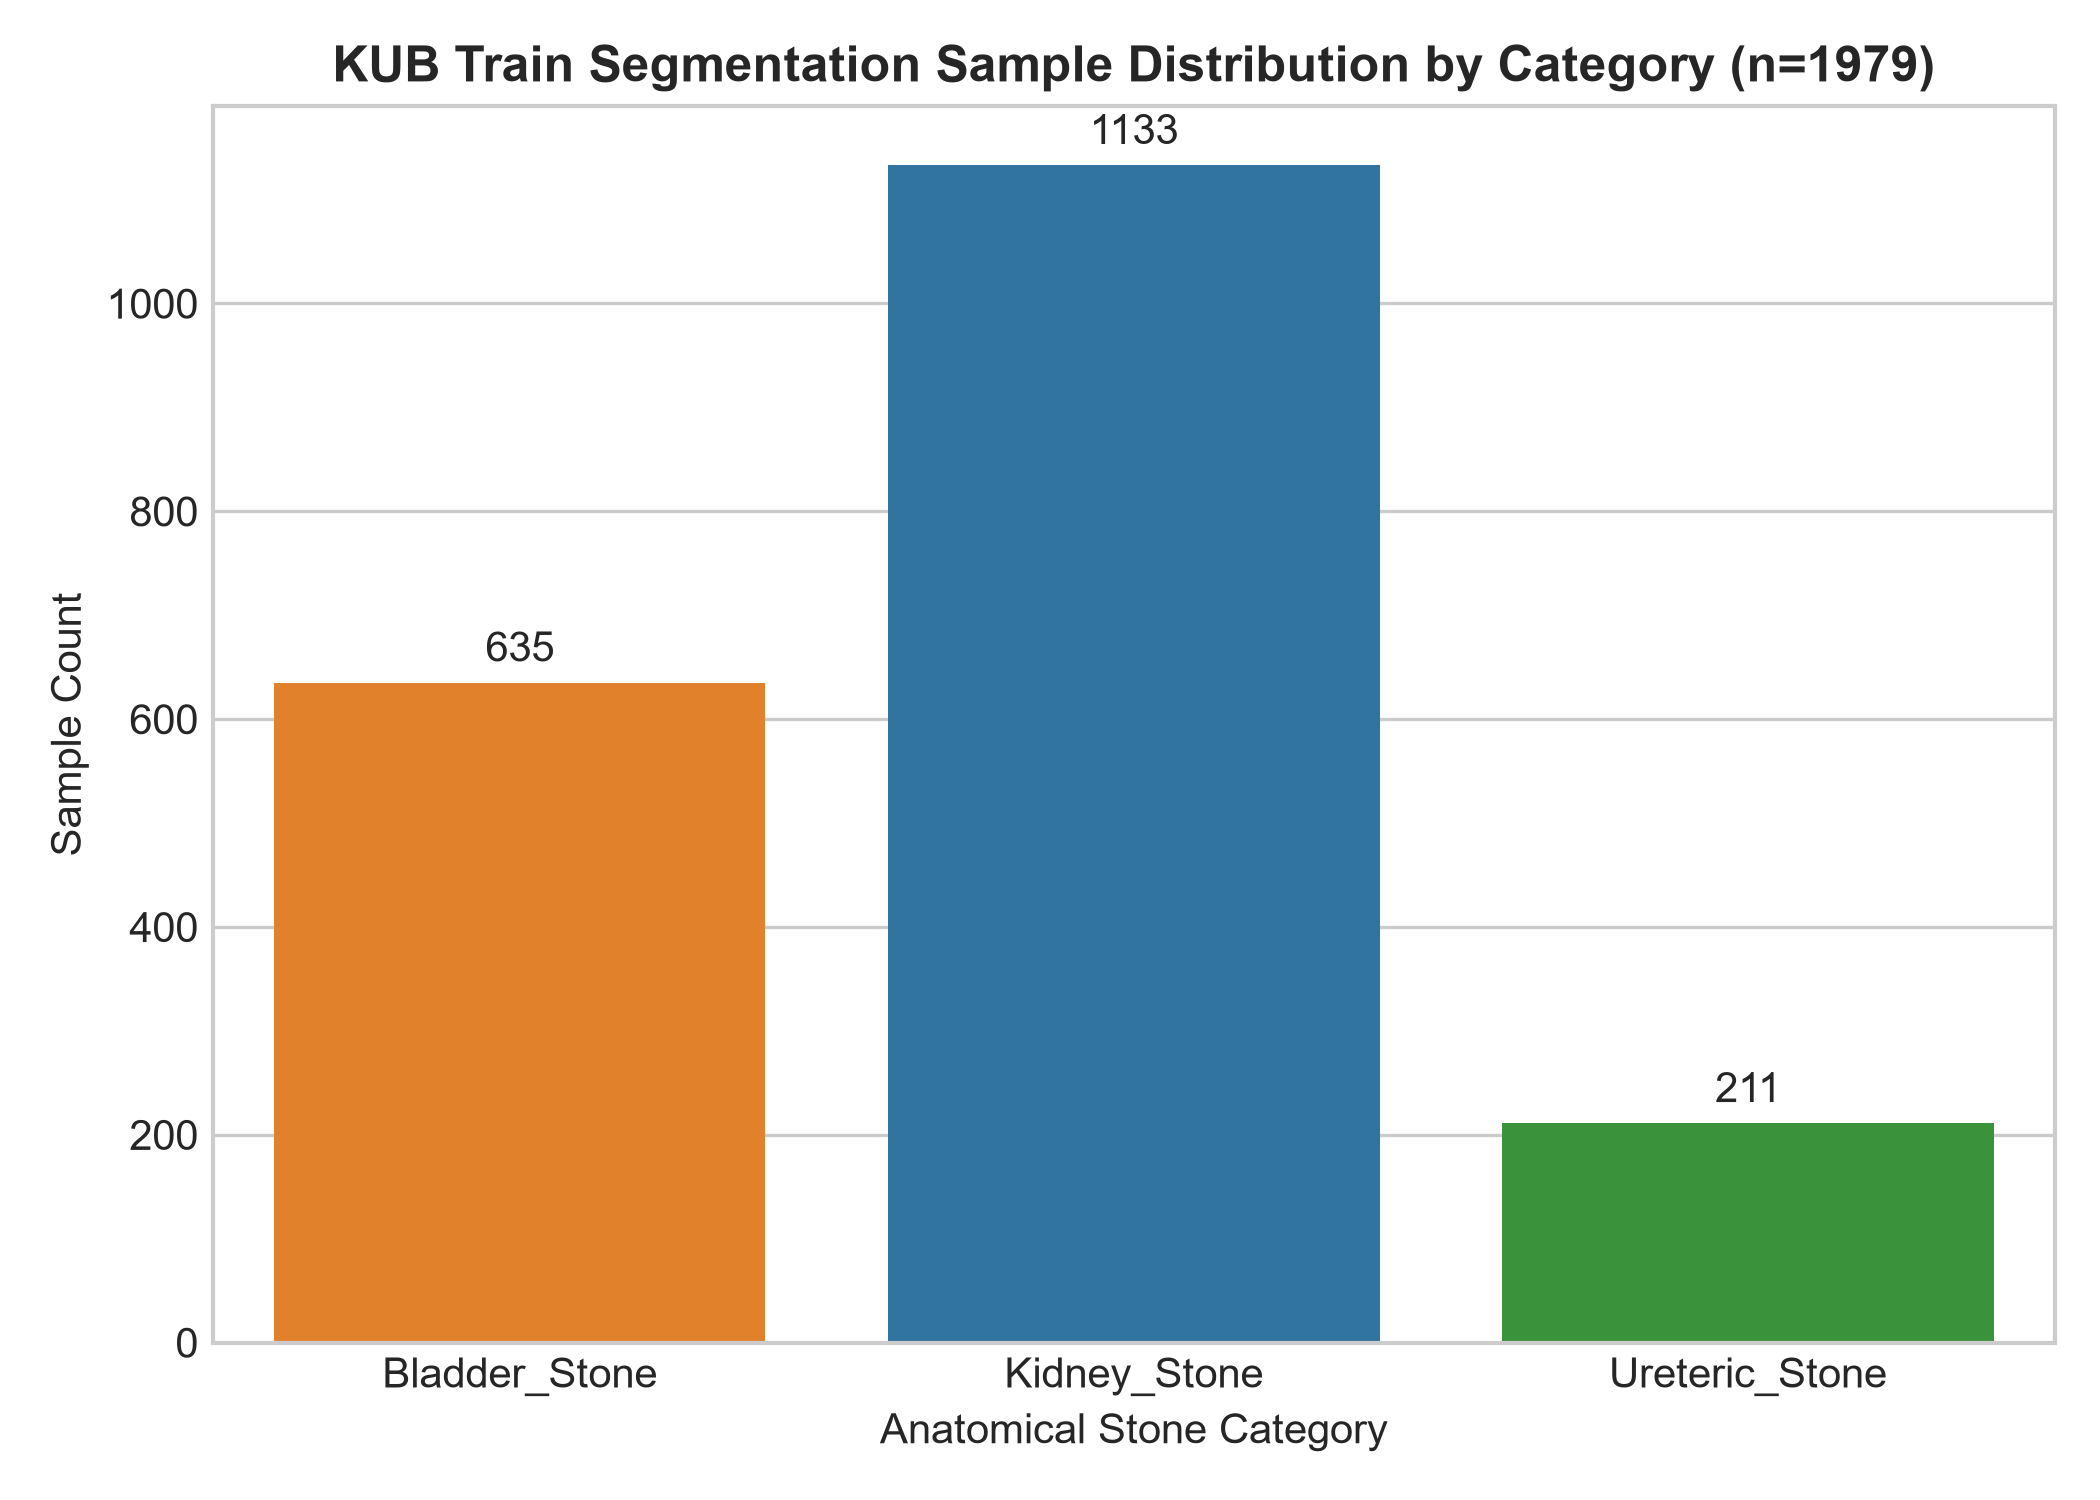

Figure B: Foreground Ratio Distribution by Category


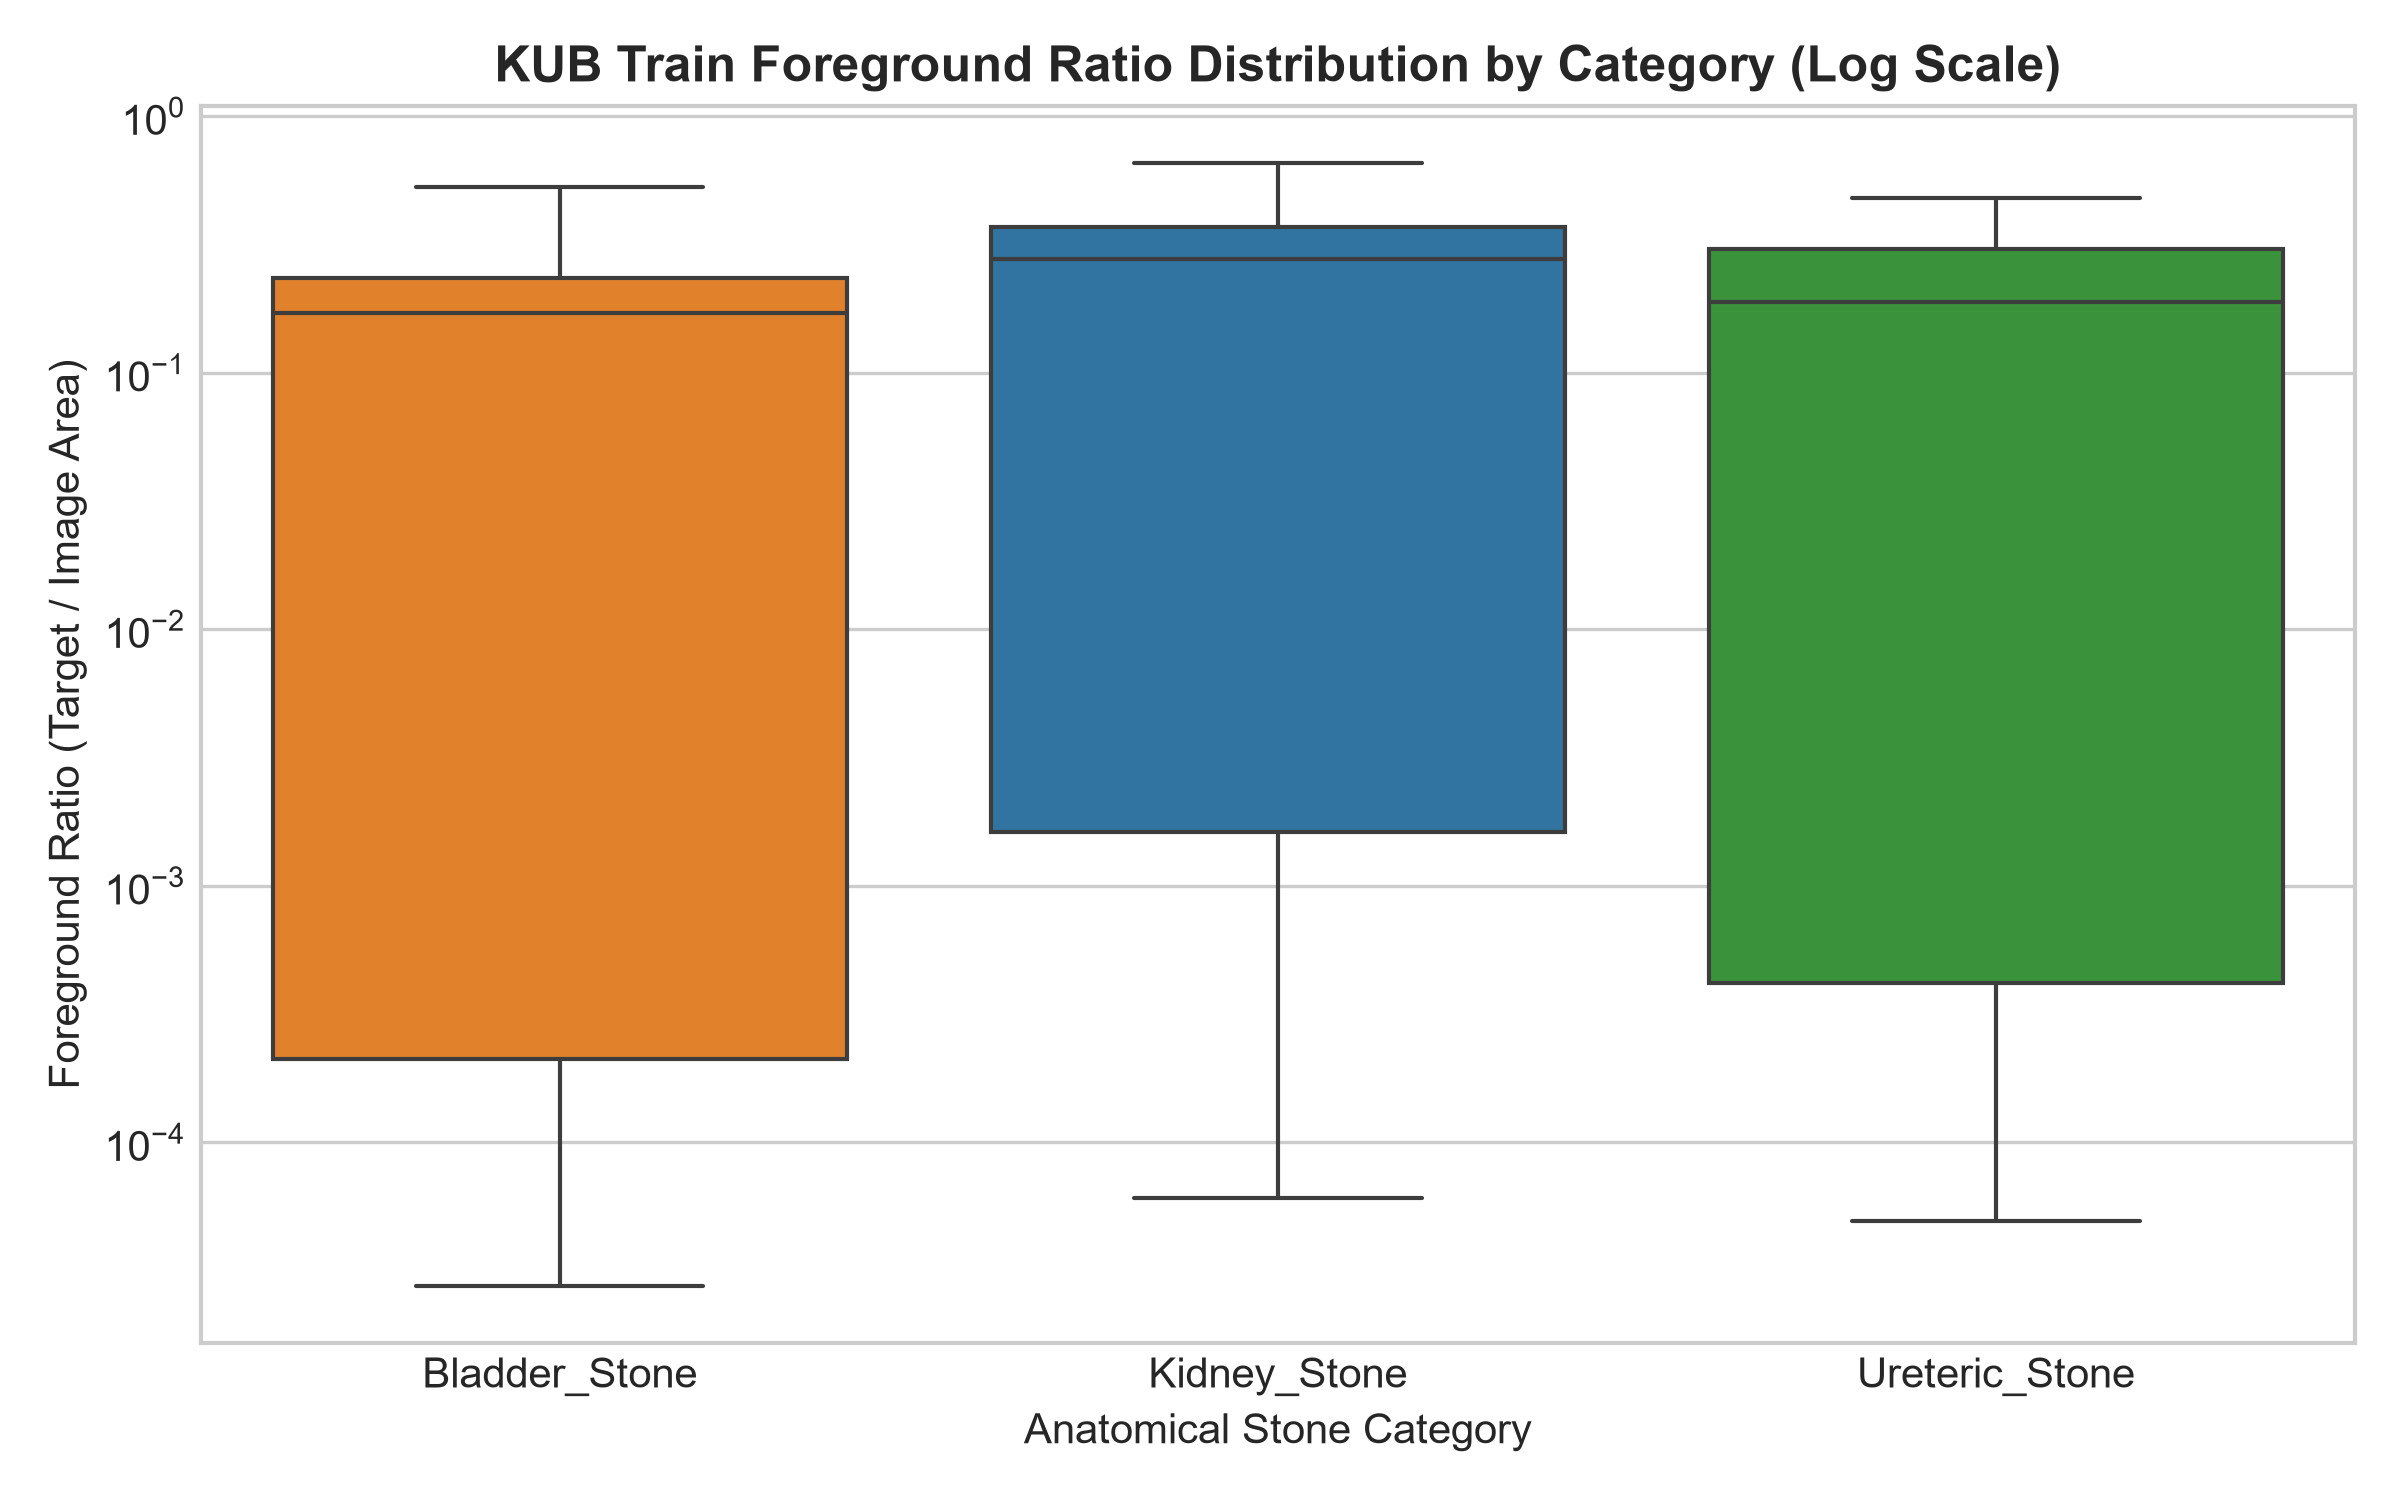

Figure C: Component Size Distribution


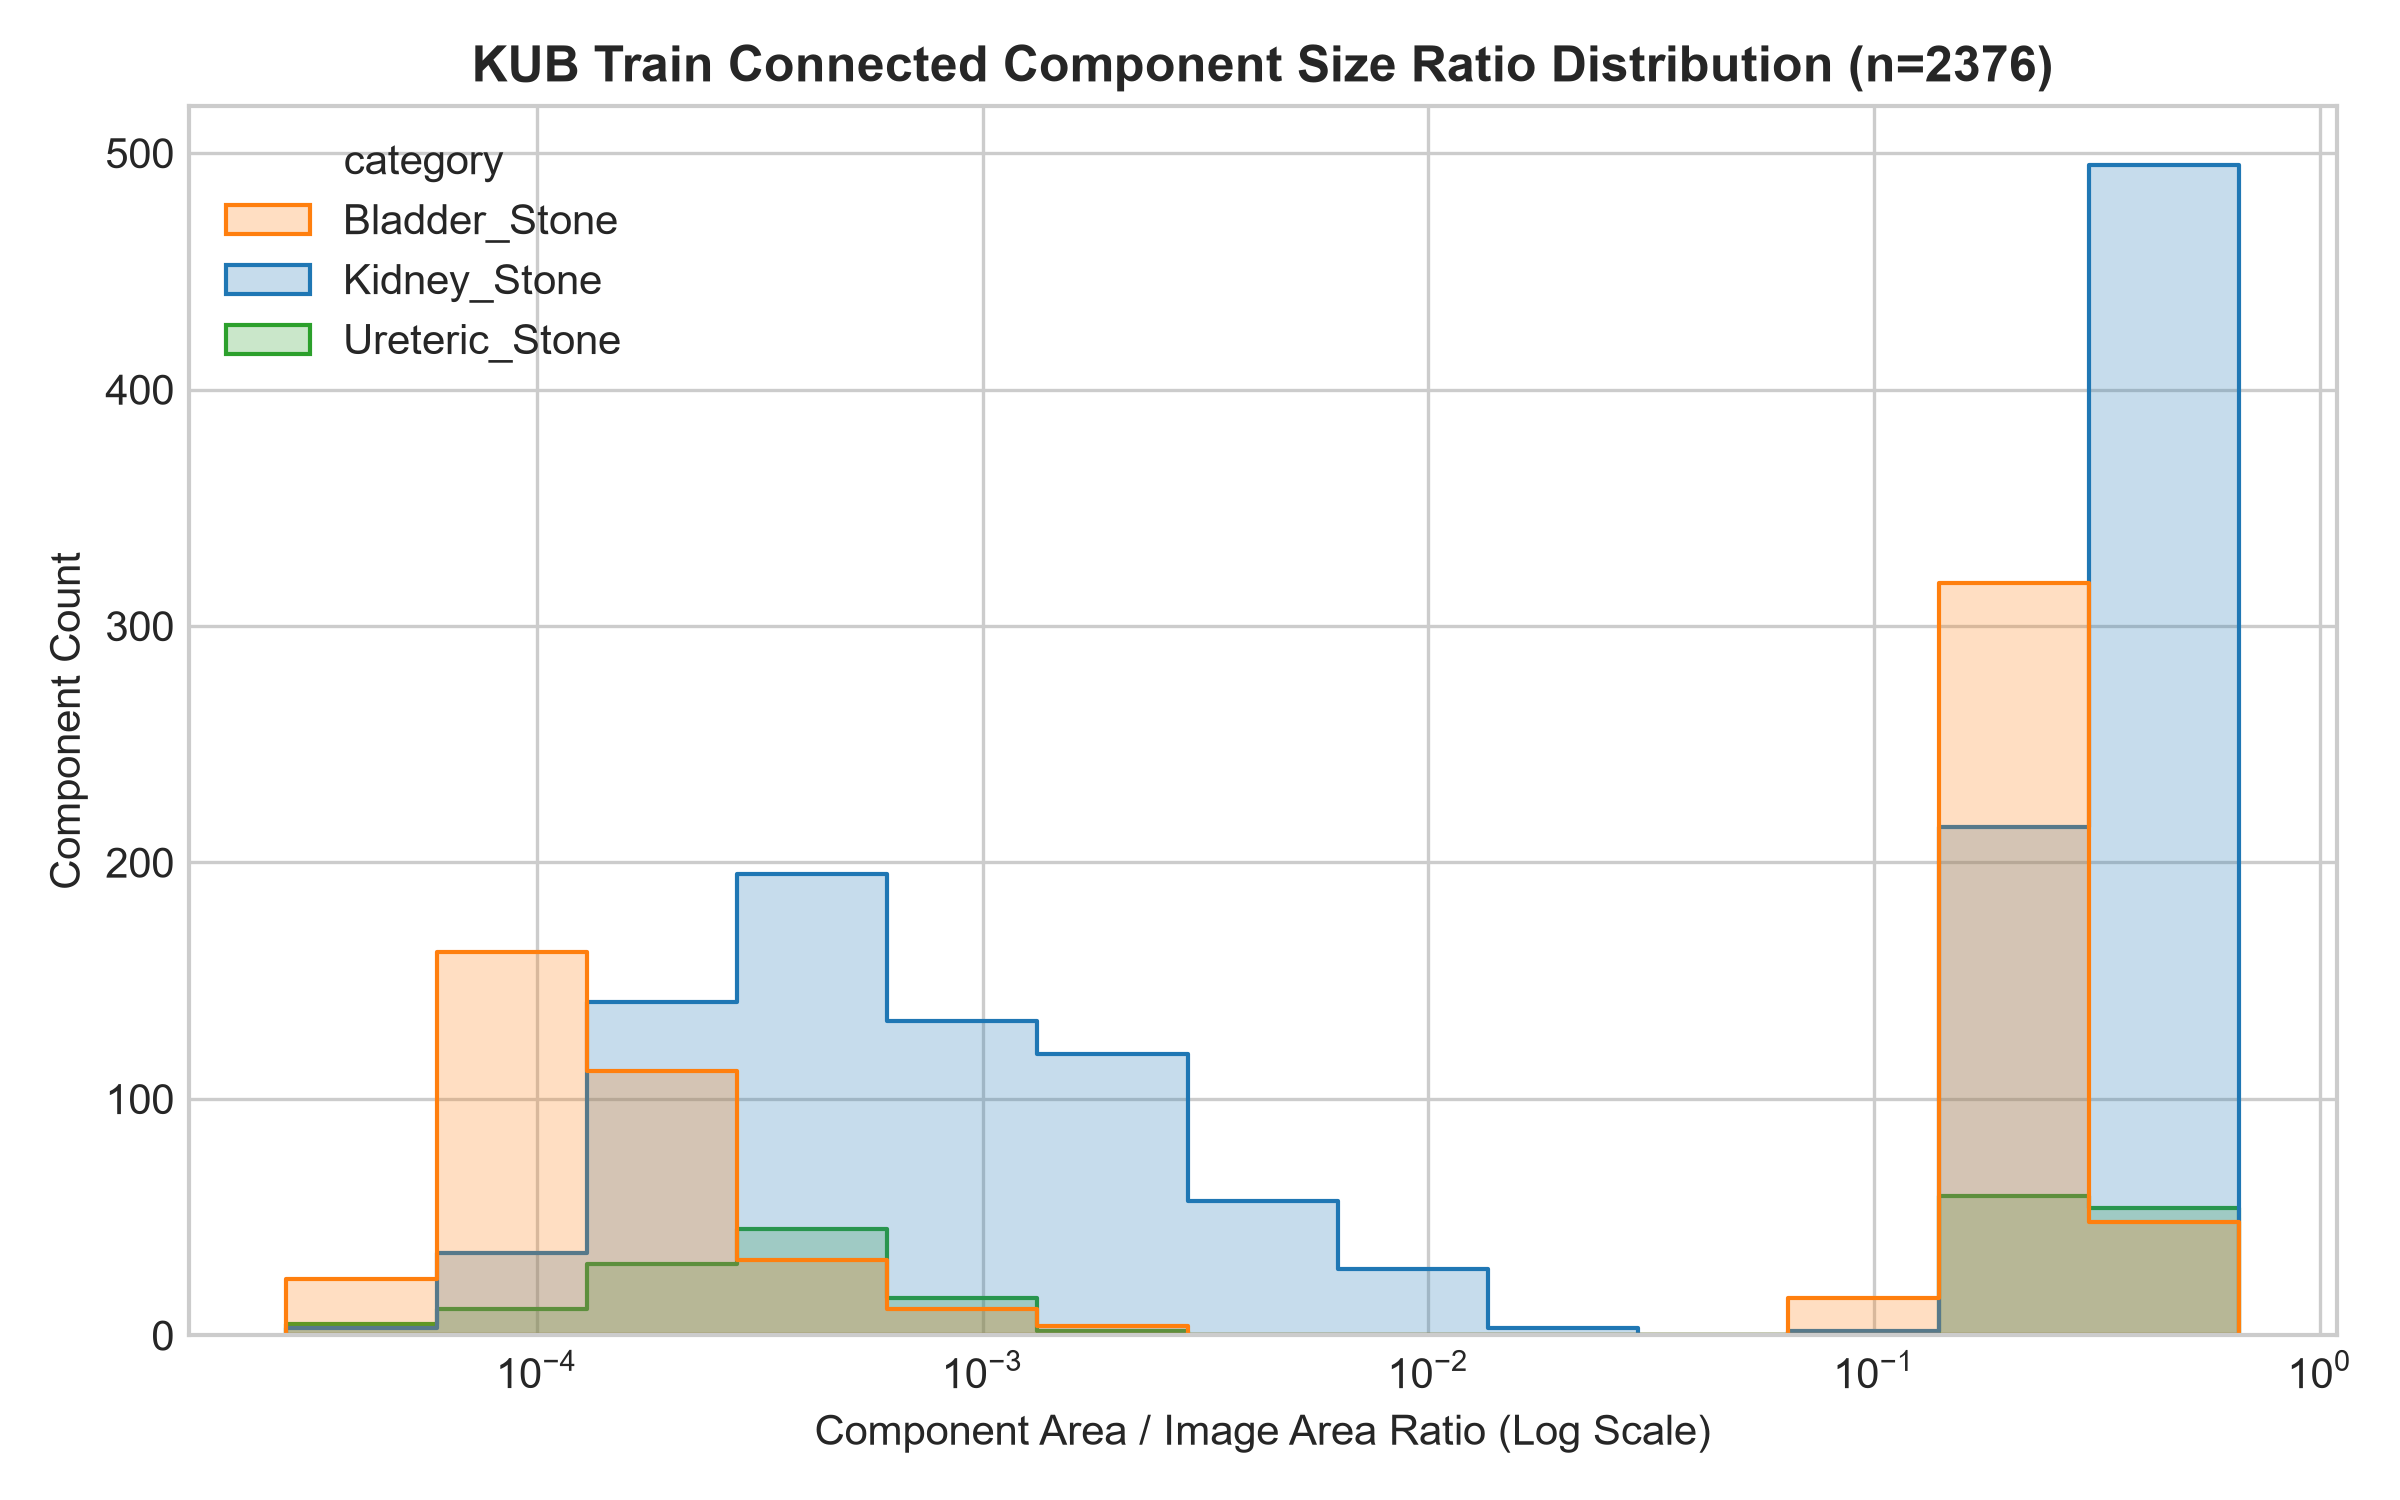

Figure D: Components per Image


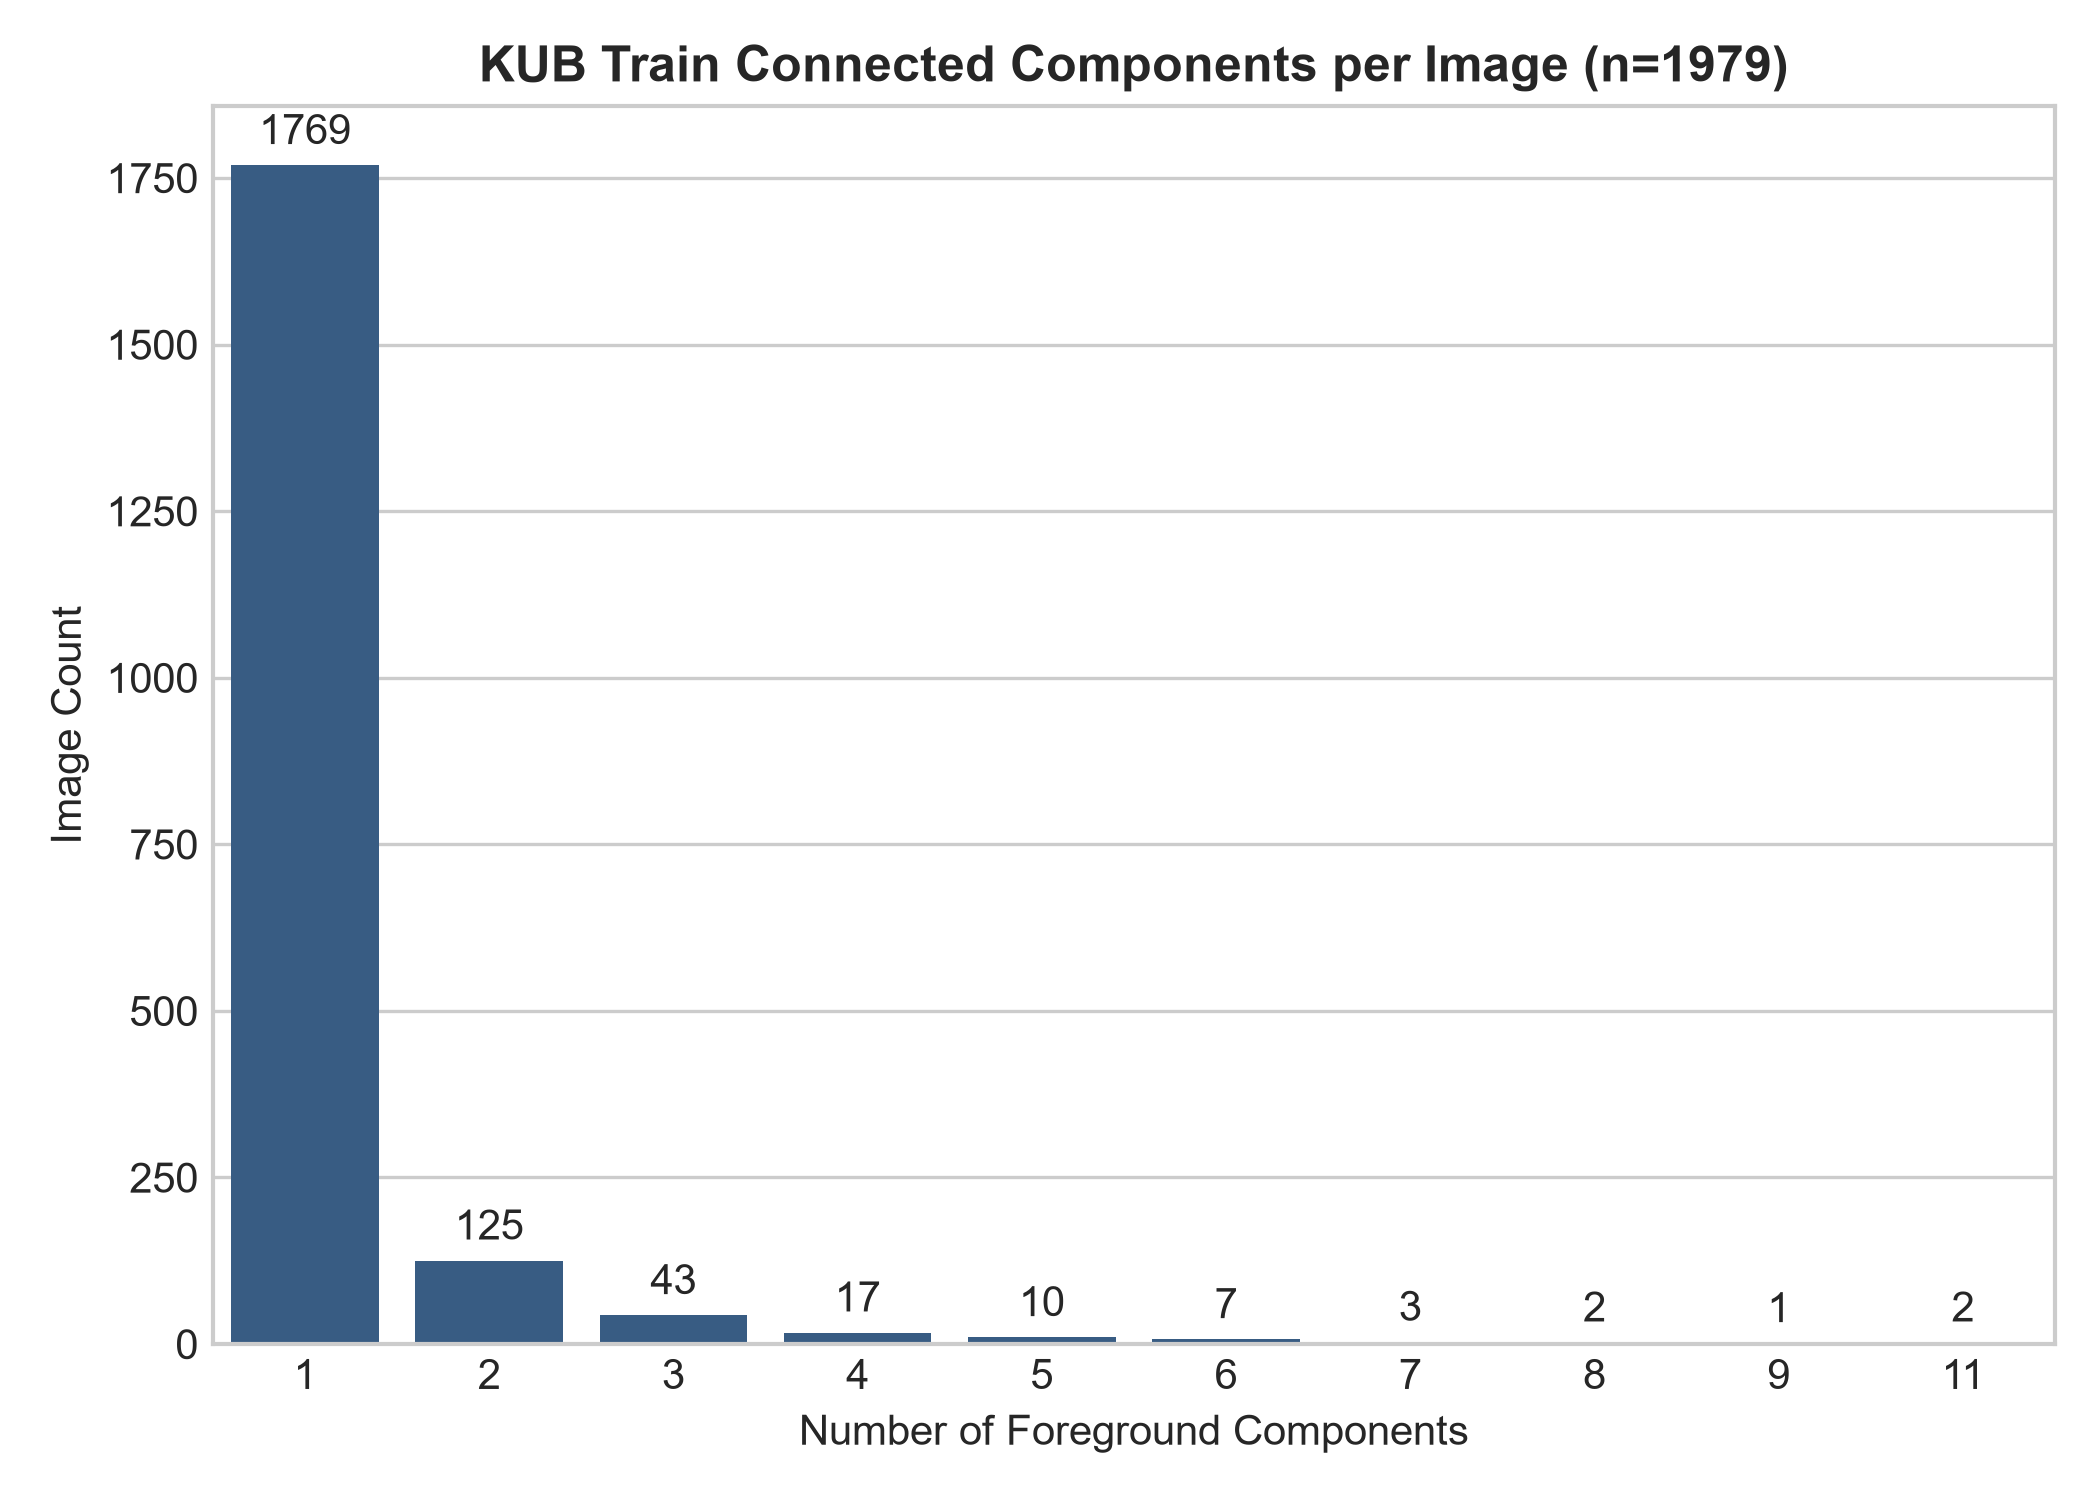

Figure E: Component Spatial Centroid Distribution


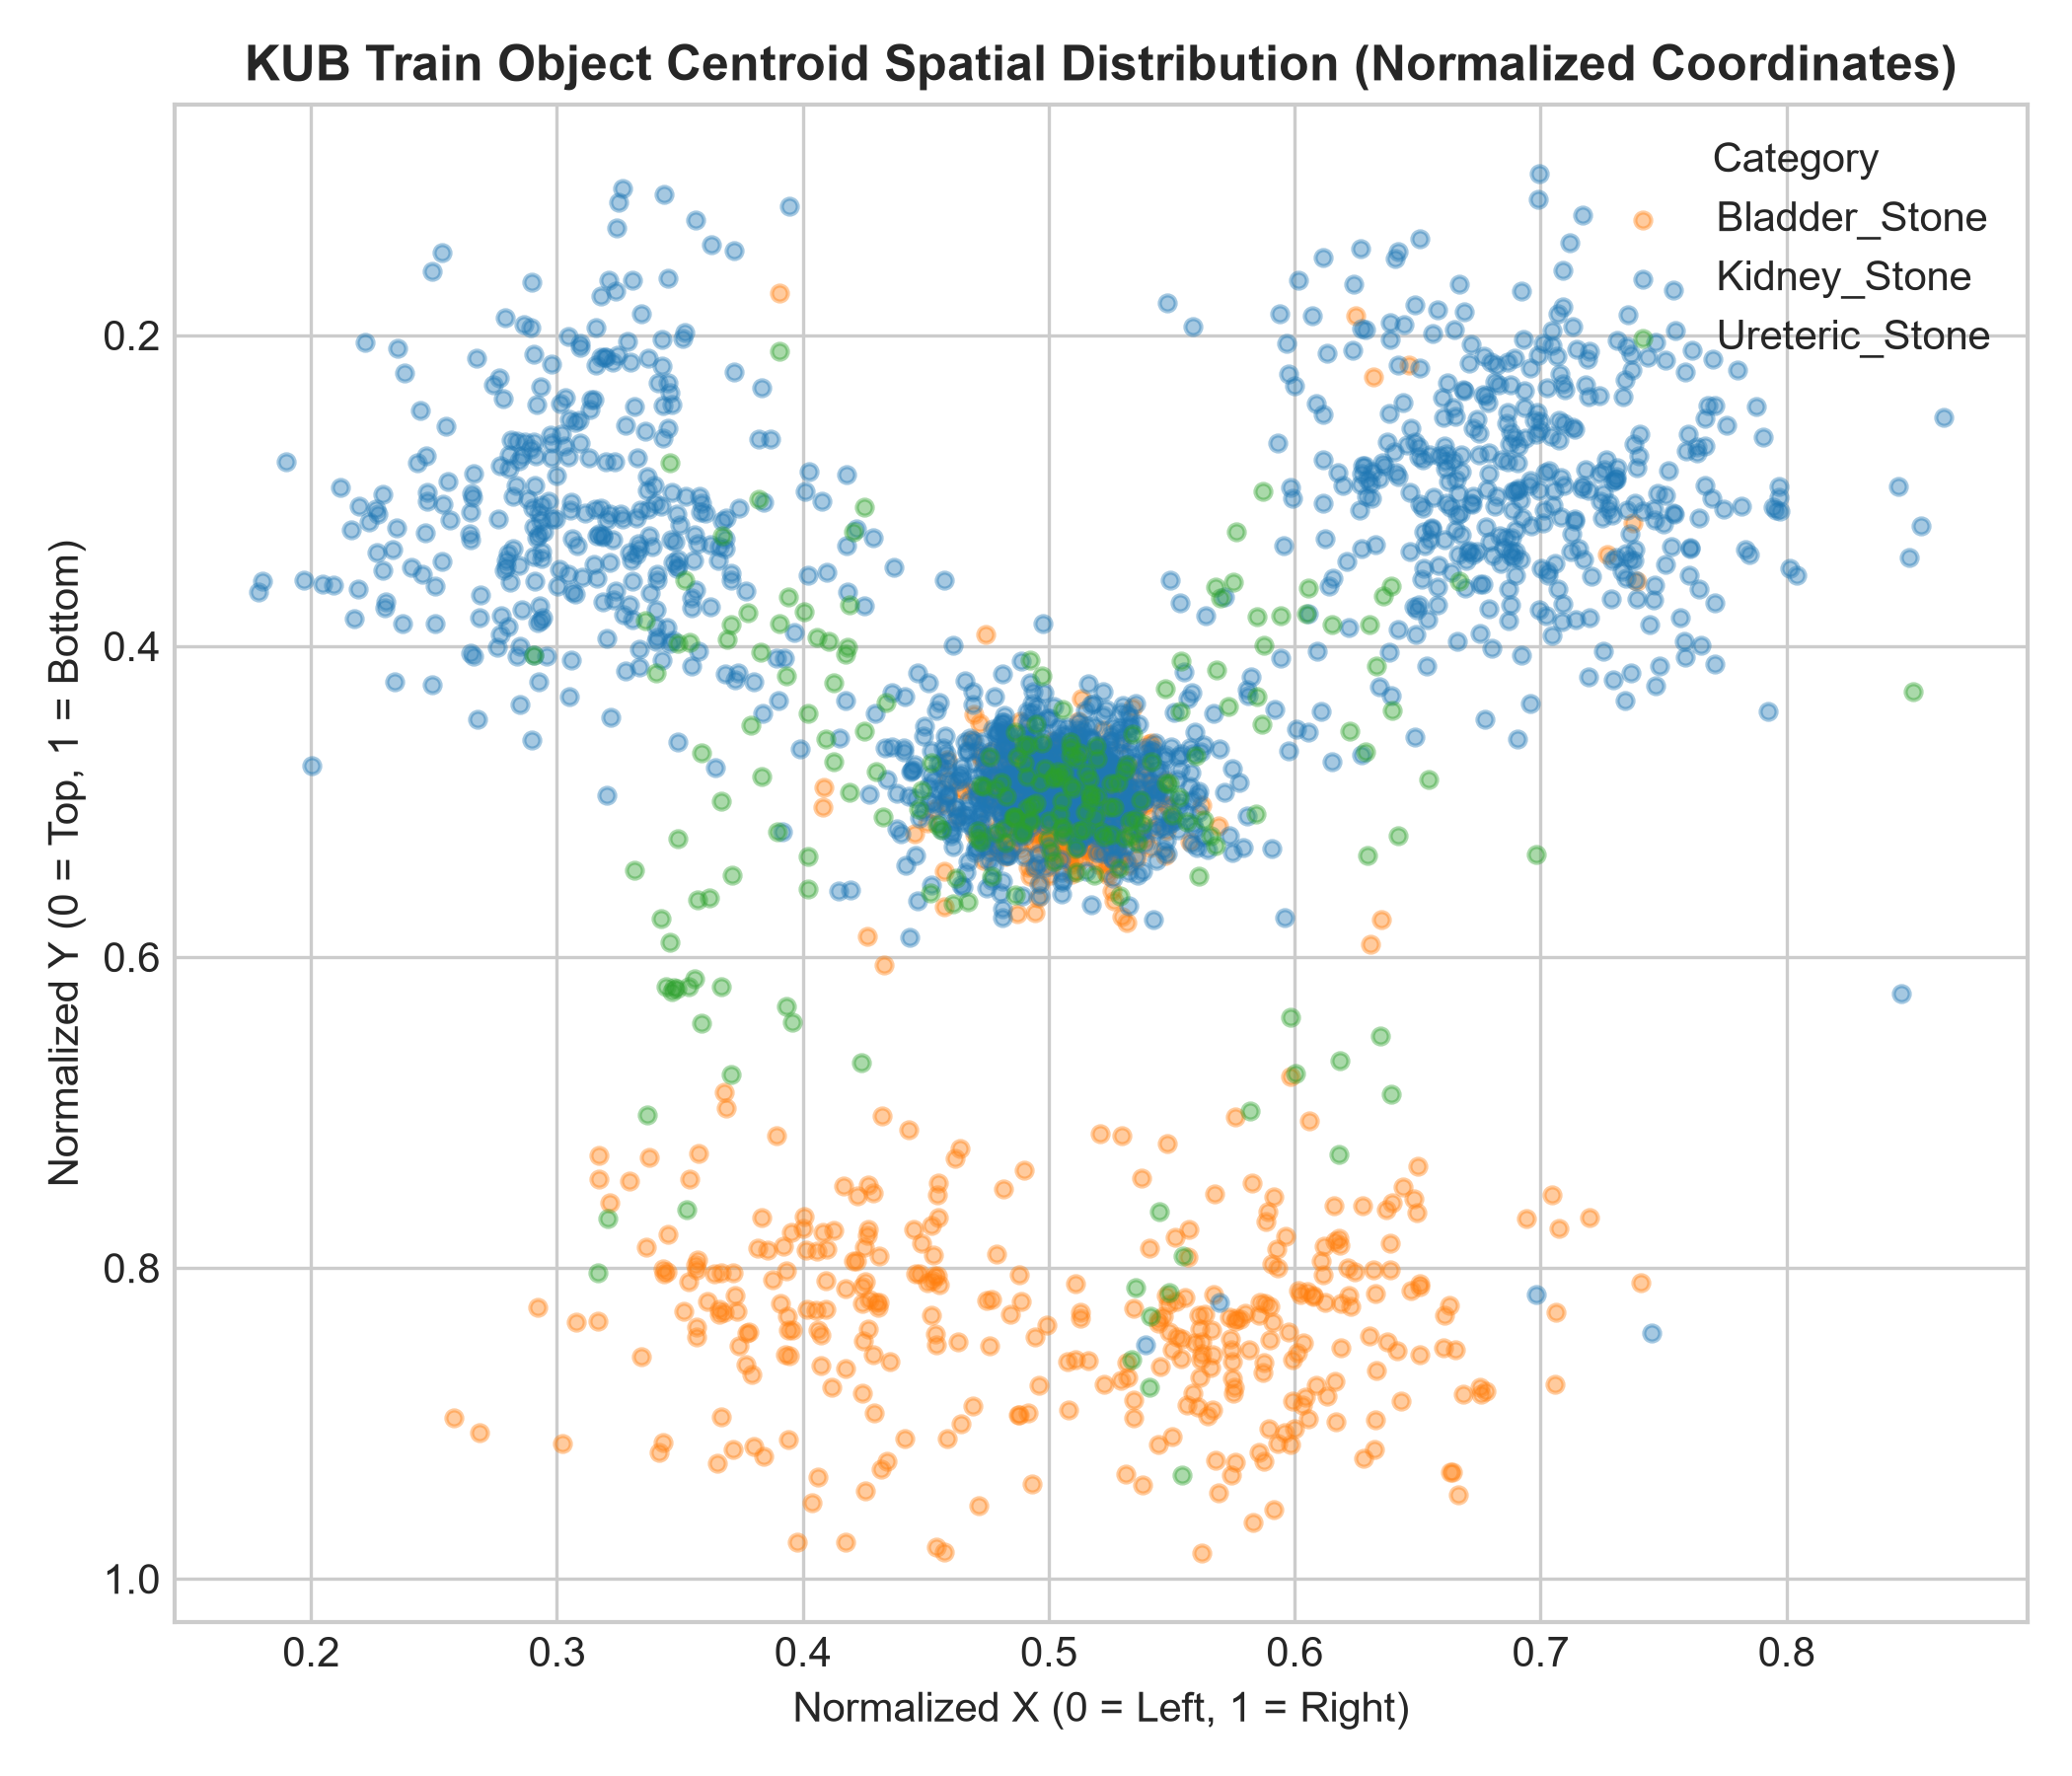

Figure F: Train vs Val Distribution Comparison


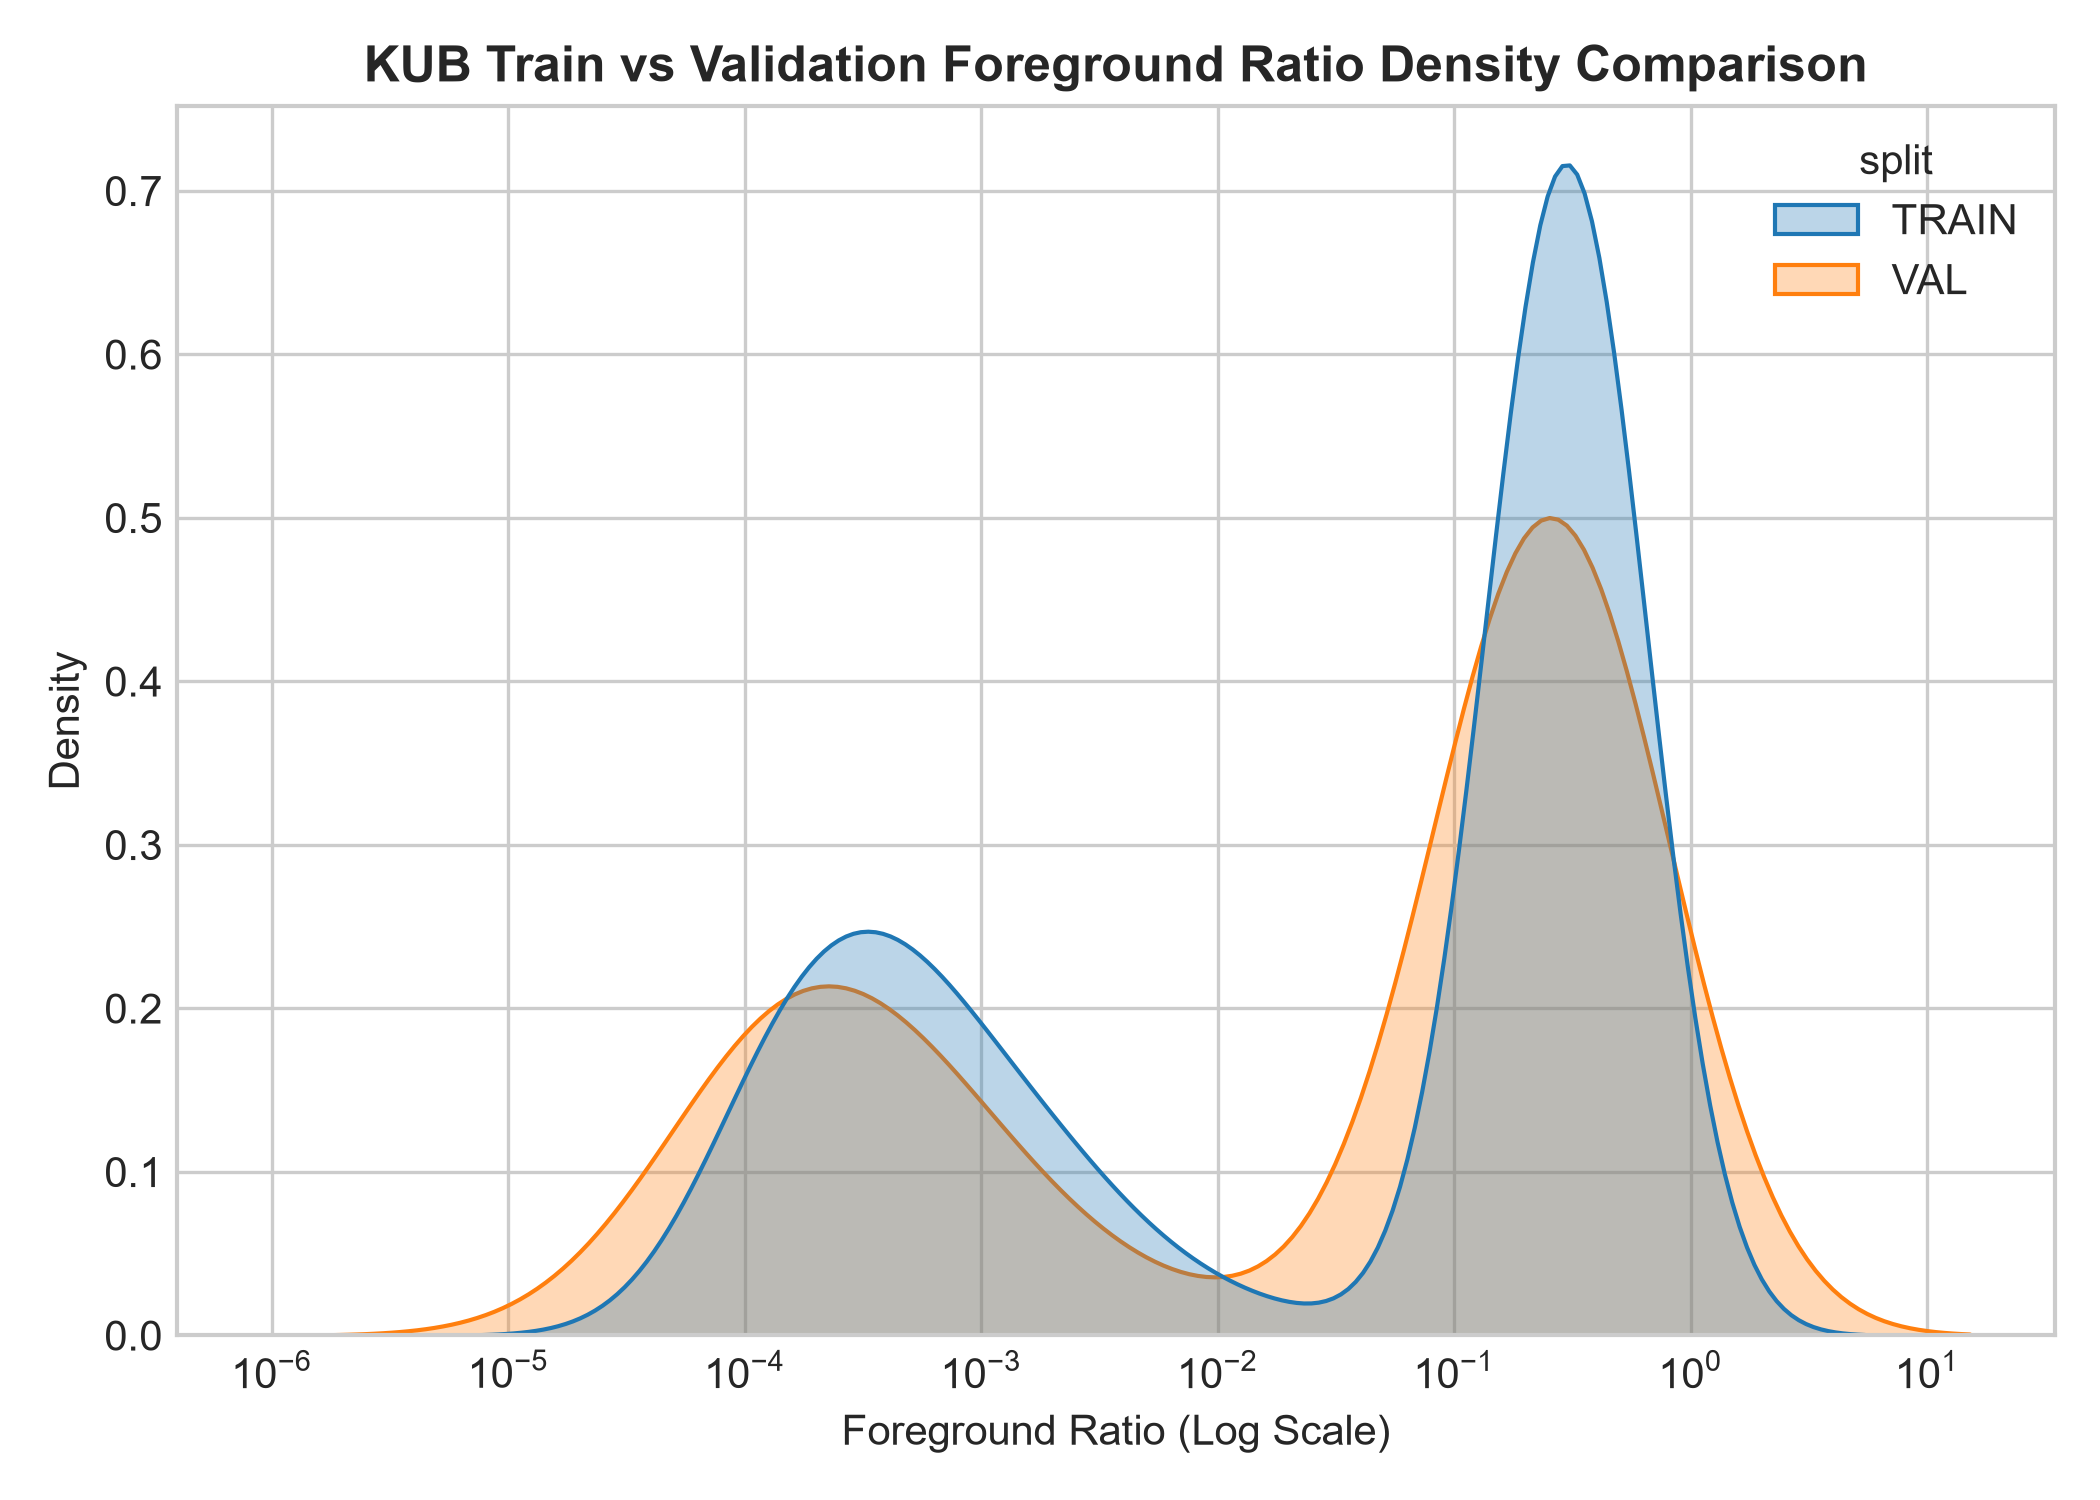

In [11]:
print('Figure A: Category Composition')
display(Image(filename=str(figures_dir / 'kub_category_composition_v2.png')))

print('Figure B: Foreground Ratio Distribution by Category')
display(Image(filename=str(figures_dir / 'kub_foreground_ratio_by_category_v2.png')))

print('Figure C: Component Size Distribution')
display(Image(filename=str(figures_dir / 'kub_component_size_distribution_v2.png')))

print('Figure D: Components per Image')
display(Image(filename=str(figures_dir / 'kub_components_per_image_v2.png')))

print('Figure E: Component Spatial Centroid Distribution')
display(Image(filename=str(figures_dir / 'kub_component_centroids_v2.png')))

print('Figure F: Train vs Val Distribution Comparison')
display(Image(filename=str(figures_dir / 'kub_train_val_distribution_v2.png')))

## Deterministic Qualitative Panel (TRAIN ONLY)

Representative samples spanning lower-tail, median, and upper-tail foreground ratios across stone categories.

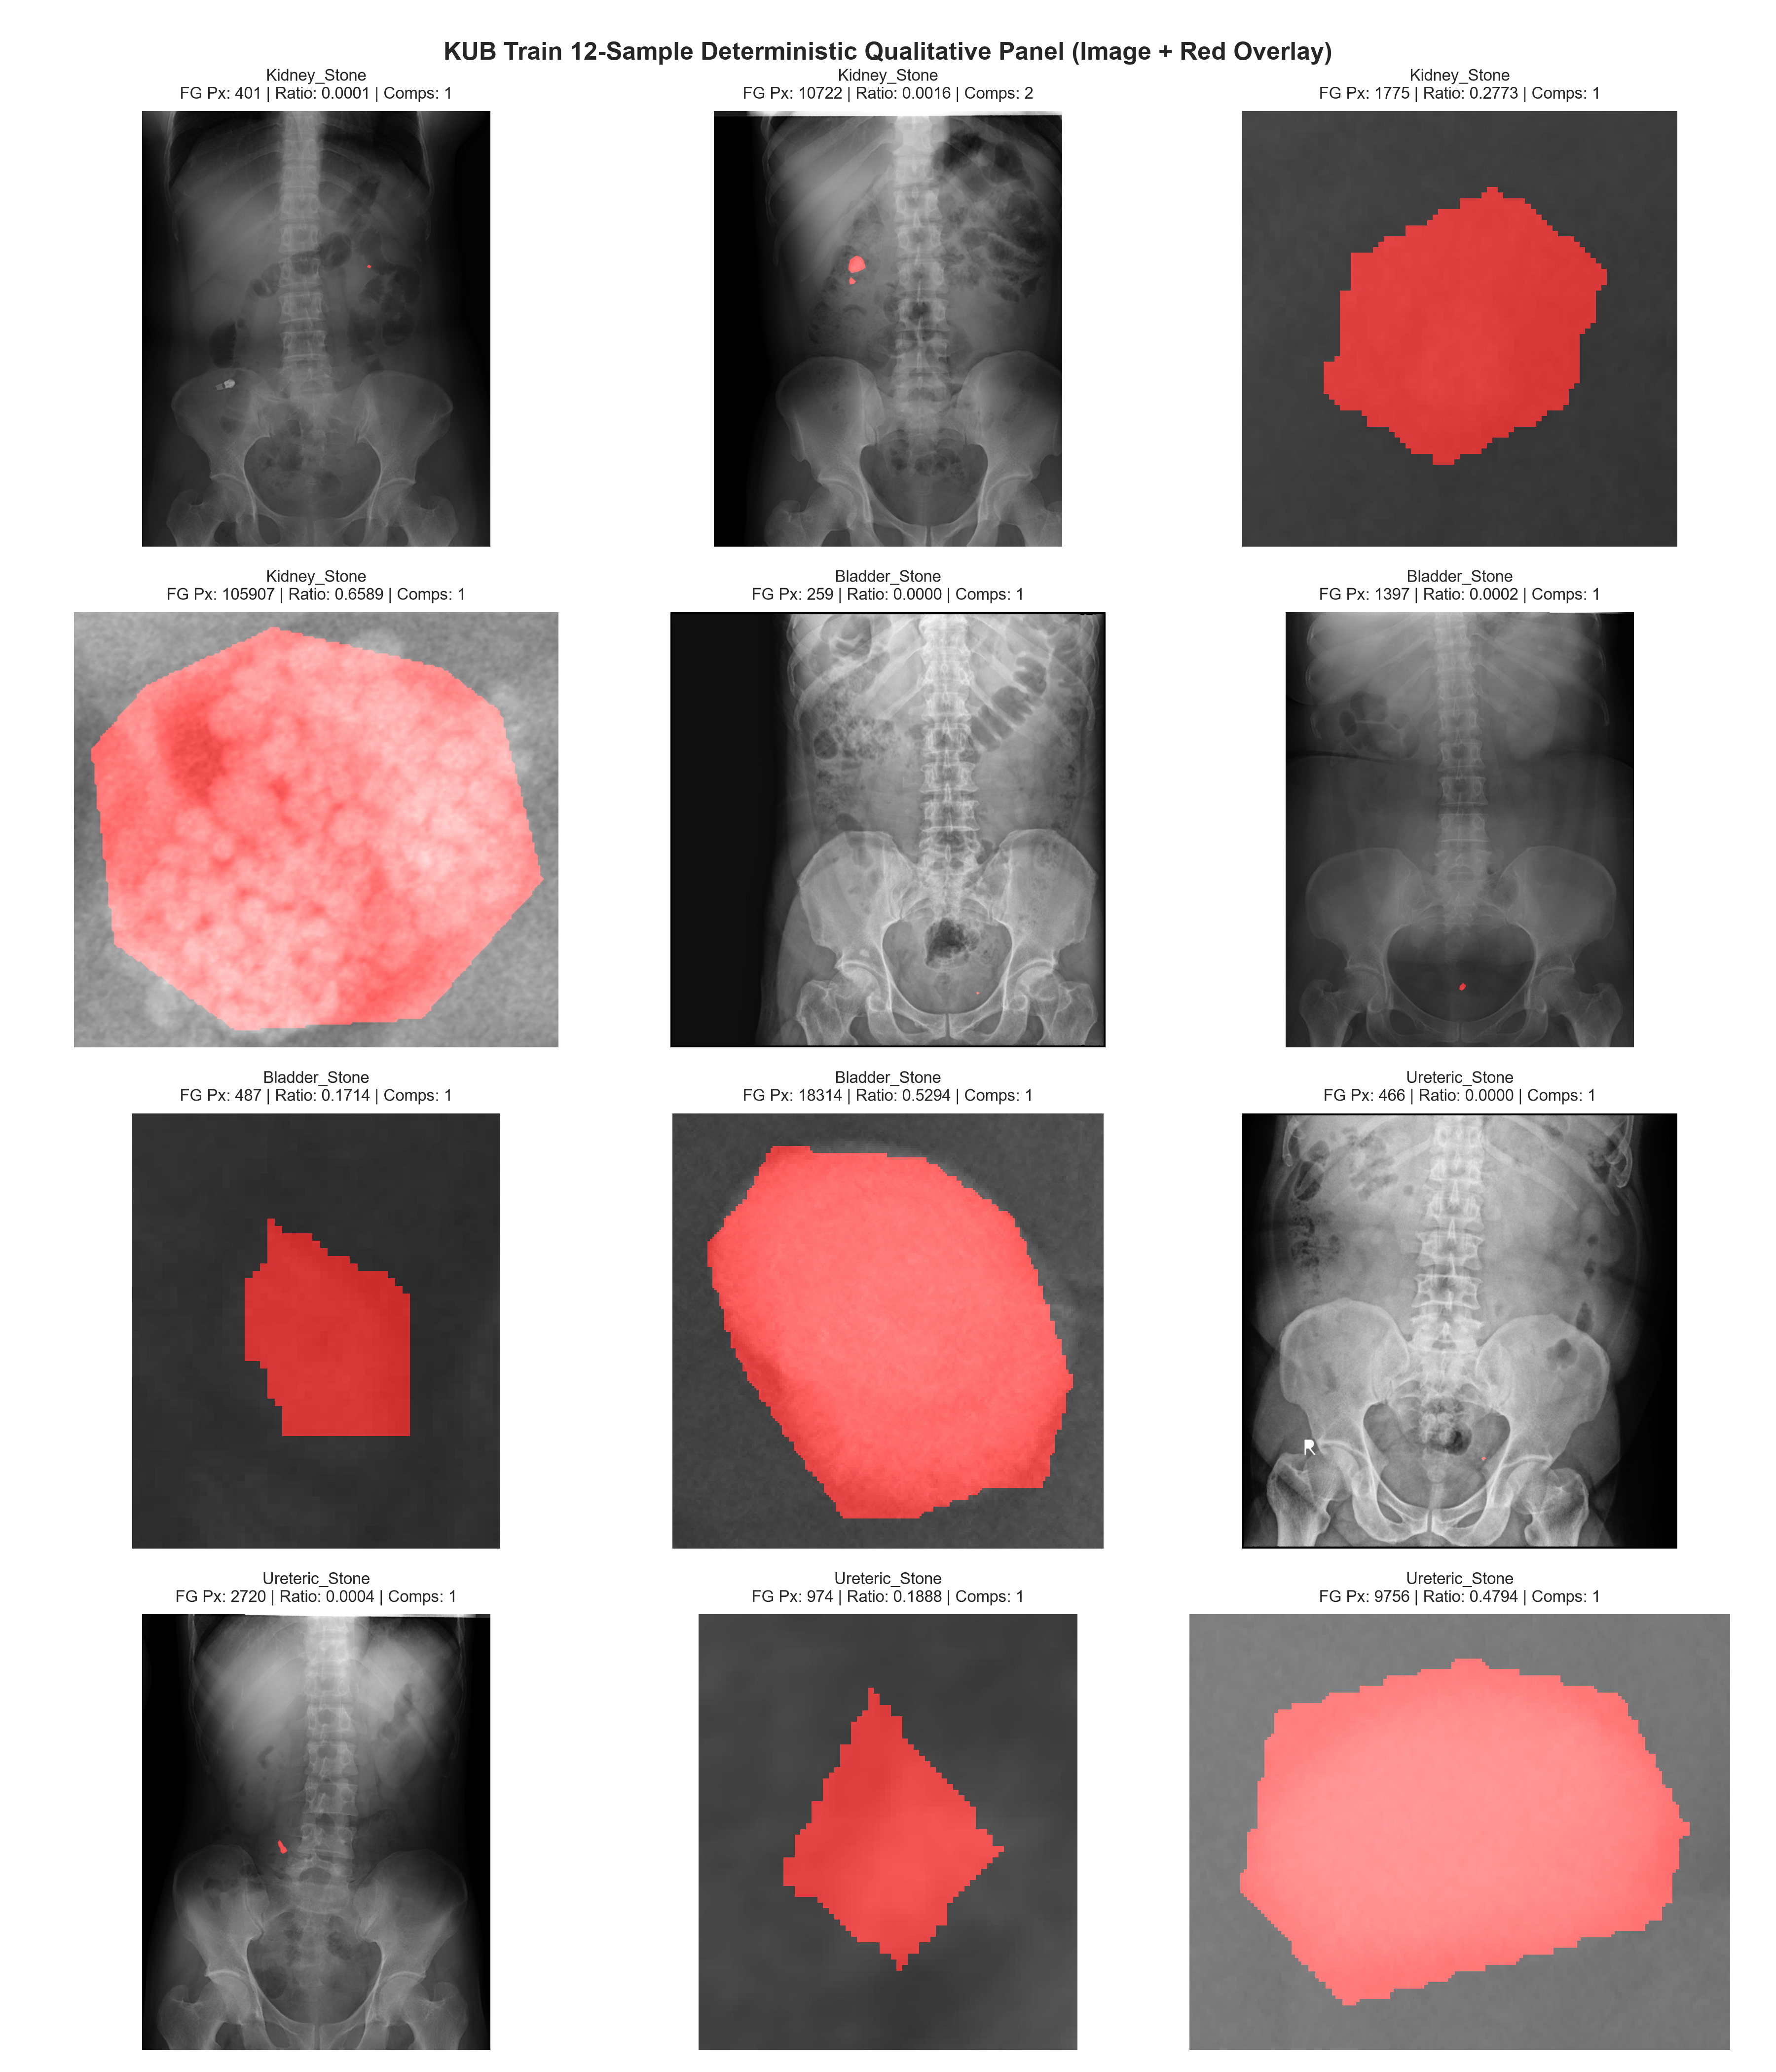

In [12]:
display(Image(filename=str(qual_dir / 'kub_train_qualitative_panel_v2.png')))

## Scientific Interpretation

1. **Analysis Population & FOV Mix**: KUB TRAIN contains 1,979 paired samples across 318 unique patients (Kidney_Stone = 1,133, Bladder_Stone = 635, Ureteric_Stone = 211). Raw image dimensions vary from 47x49 cropped ROIs to 3096x3528 radiography plates (median width = 141, height = 154).
2. **Foreground Ratio & Semantics**: Measured foreground ratios (`foreground = (mask > 0)`) span from 0.000027 to 0.658871 (median = 0.209896). The elevated median foreground ratio is due to the presence of cropped ROI cutouts in the raw KUB dataset.
3. **Connected Components**: 8-connectivity labeling yields 2,376 total components (mean = 1.20 components/image, max = 11). 210 images (10.6%) contain multiple distinct foreground components.
4. **Spatial Localization**: Normalized centroids demonstrate clear anatomical distribution (Bladder y_norm median = 0.5374, Kidney y_norm median = 0.4356, Ureteric y_norm median = 0.4964).
5. **Train vs Val Density**: Kernel density estimations show consistent distribution alignment between TRAIN (median ratio = 0.209896) and VAL (median ratio = 0.186214).